In [32]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

In [9]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "ai4i2020.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

C:\Users\HP\AppData\Local\Temp\ipykernel_12476\4073655220.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    

In [3]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [26]:
print(df["Type"])

0       M
1       L
2       L
3       L
4       L
       ..
9995    M
9996    H
9997    M
9998    H
9999    M
Name: Type, Length: 10000, dtype: str


In [8]:
display(df)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [12]:
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate UDIs:", df["UDI"].duplicated().sum())

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0
Duplicate UDIs: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64 
 Machine failure
0    96.61
1     3.39
Name: count, dtype: float64


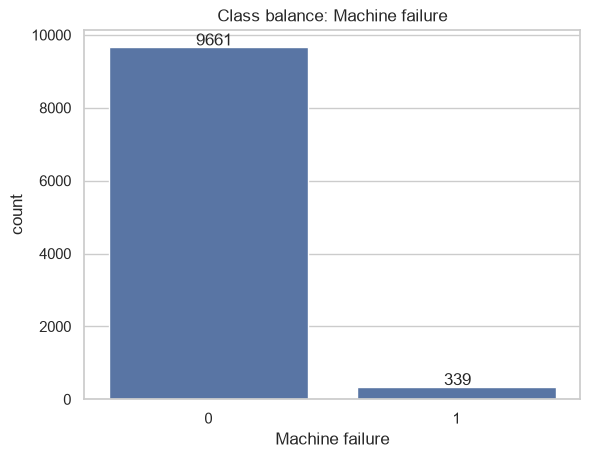

In [14]:
counts = df["Machine failure"].value_counts()
print(counts, "\n", (counts / len(df) * 100).round(2))

ax = sns.countplot(x="Machine failure", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+0.35, p.get_height()+50))
plt.title("Class balance: Machine failure")
plt.show()

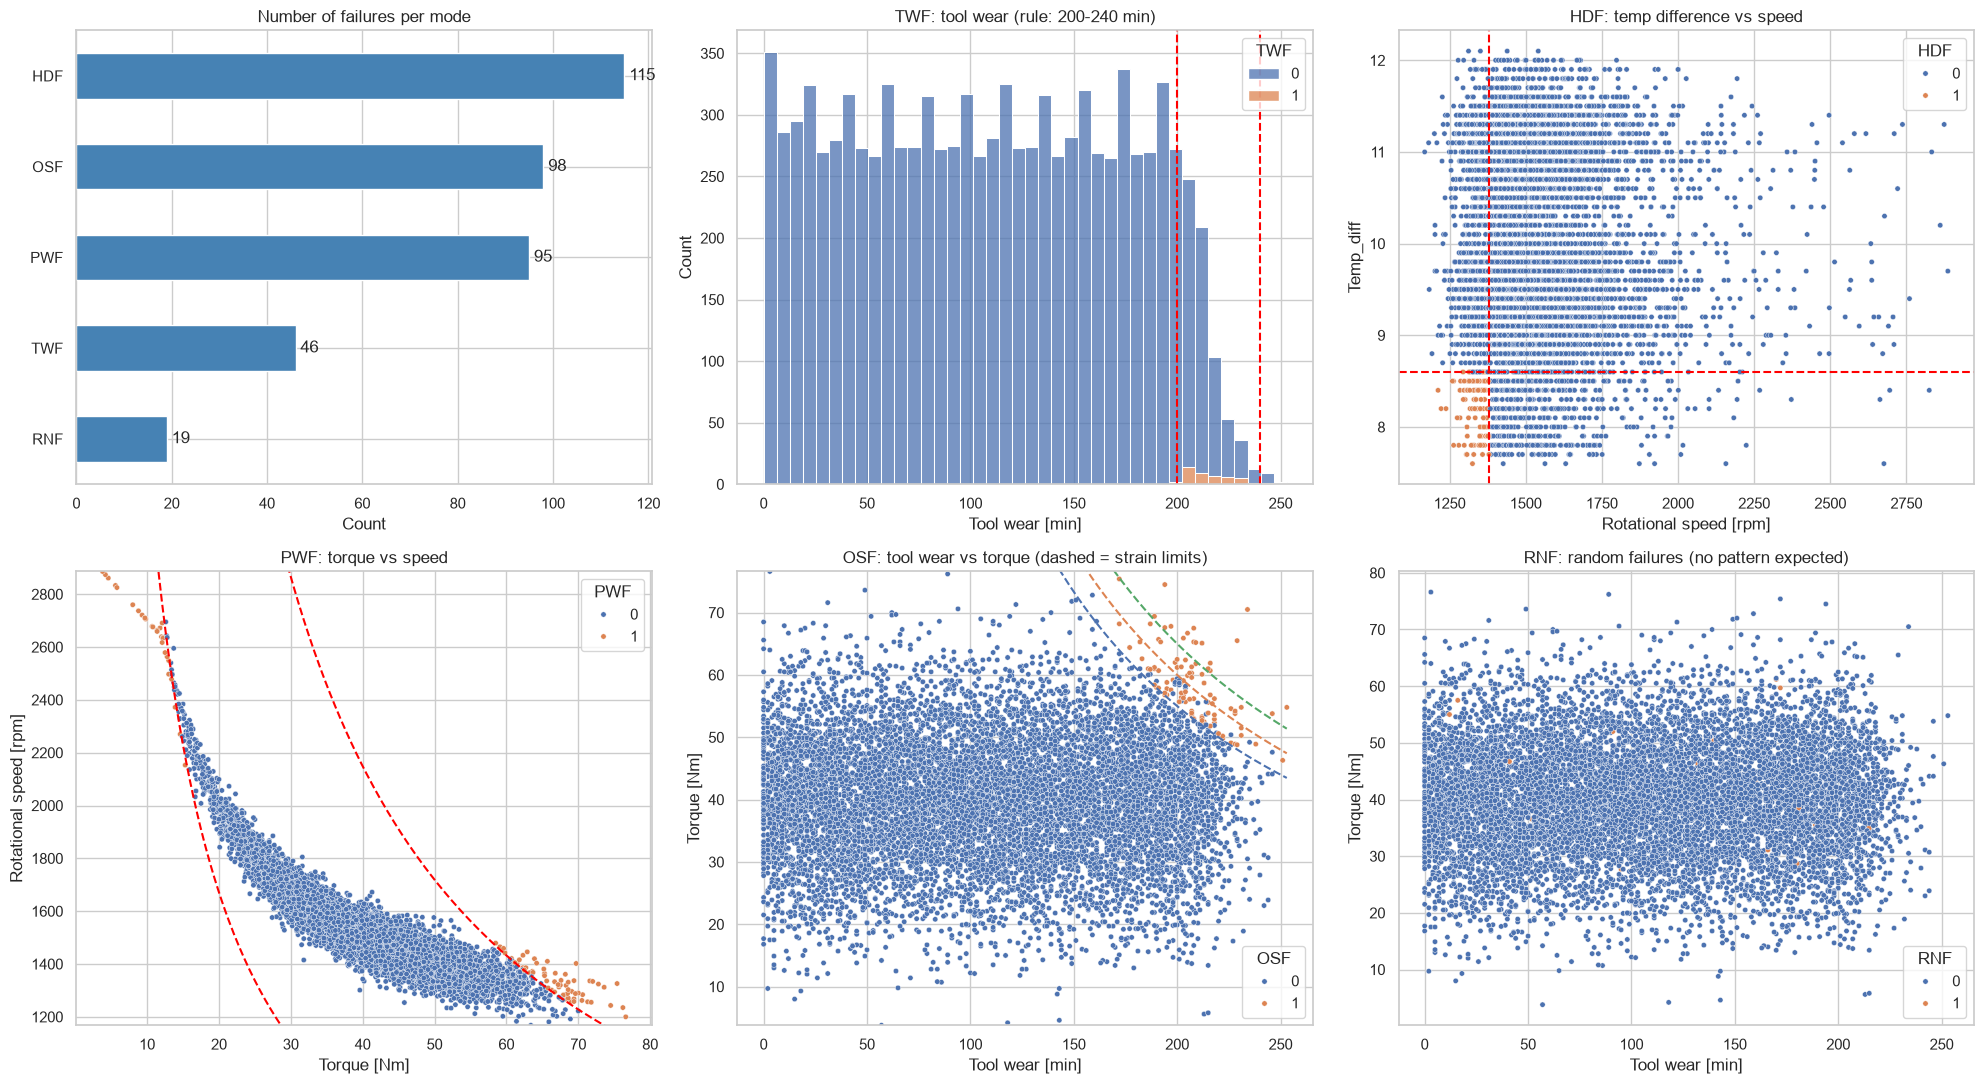

In [17]:
sns.set_theme(style="whitegrid")

# Original column names (no renaming needed)
air, proc = "Air temperature [K]", "Process temperature [K]"
rpm, tq, wear = "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Helper features that mirror the failure rules
df["Temp_diff"] = df[proc] - df[air]
df["Power"] = df[tq] * df[rpm] * 2 * np.pi / 60
df["Strain"] = df[wear] * df[tq]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

# 1) Count of each failure mode
counts = df[modes].sum().sort_values()
counts.plot(kind="barh", ax=axes[0], color="steelblue")
for i, v in enumerate(counts):
    axes[0].text(v + 1, i, int(v), va="center")
axes[0].set_title("Number of failures per mode")
axes[0].set_xlabel("Count")

# 2) TWF: tool wear (failures expected between 200 and 240 min)
sns.histplot(data=df, x=wear, hue="TWF", bins=40, multiple="stack", ax=axes[1])
axes[1].axvline(200, color="red", ls="--"); axes[1].axvline(240, color="red", ls="--")
axes[1].set_title("TWF: tool wear (rule: 200-240 min)")

# 3) HDF: temperature difference < 8.6 K and speed < 1380 rpm
sns.scatterplot(data=df, x=rpm, y="Temp_diff", hue="HDF", s=15, ax=axes[2])
axes[2].axhline(8.6, color="red", ls="--"); axes[2].axvline(1380, color="red", ls="--")
axes[2].set_title("HDF: temp difference vs speed")

# 4) PWF: power < 3500 W or > 9000 W
sns.scatterplot(data=df, x=tq, y=rpm, hue="PWF", s=15, ax=axes[3])
axes[3].set_title("PWF: torque vs speed")
axes[3].set_ylim(df[rpm].min(), df[rpm].max())
# power-threshold curves: rpm = P * 60 / (2*pi*torque)
t = np.linspace(max(df[tq].min(), 1), df[tq].max(), 300)
for P in (3500, 9000):
    axes[3].plot(t, P * 60 / (2 * np.pi * t), color="red", ls="--")

# 5) OSF: strain above 11000 (L), 12000 (M), 13000 (H)
sns.scatterplot(data=df, x=wear, y=tq, hue="OSF", s=15, ax=axes[4])
w = np.linspace(max(df[wear].min(), 1), df[wear].max(), 300)
for lim in (11000, 12000, 13000):
    axes[4].plot(w, lim / w, ls="--", label=f"{lim}")
axes[4].set_ylim(df[tq].min(), df[tq].max())
axes[4].set_title("OSF: tool wear vs torque (dashed = strain limits)")

# 6) RNF: random by design, so no rule region is expected
sns.scatterplot(data=df, x=wear, y=tq, hue="RNF", s=15, ax=axes[5])
axes[5].set_title("RNF: random failures (no pattern expected)")

plt.tight_layout()
plt.show()

In [24]:
print(np.unique(df['Machine failure']))

[0 1]


In [107]:
features = ['Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
# drop : UID, Product ID, 'TWF', 'HDF', 'PWF', 'OSF', 'RNF' -> the five last columns are about the type of Machine failure

x = df[features].copy()
y = df["Machine failure"]
print(x.shape)
print(y.shape)

(10000, 6)
(10000,)


In [108]:
# change from str to int64
x["Type"] = x["Type"].map({"L": 0, "M": 1, "H": 2})

In [109]:
display(x)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,0,298.2,308.7,1408,46.3,3
2,0,298.1,308.5,1498,49.4,5
3,0,298.2,308.6,1433,39.5,7
4,0,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,1,298.8,308.4,1604,29.5,14
9996,2,298.9,308.4,1632,31.8,17
9997,1,299.0,308.6,1645,33.4,22
9998,2,299.0,308.7,1408,48.5,25


In [110]:
print(x["Type"].unique())   # Option A: should show [1 0 2], no NaN
print(x.dtypes)             # no 'object' columns left
print(x.isna().sum())       # all zeros

[1 0 2]
Type                         int64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


In [111]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=55, stratify=y
)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (8000, 6)
Testing data shape: (2000, 6)


In [112]:
print(y_train.value_counts())
print(y_test.value_counts())

Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [173]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

In [114]:
def model_eval(y_predict, y_test):
    print(classification_report(y_test, y_predict, target_names=["No failure", "Failure"], digits=3))
    cm = confusion_matrix(y_test, y_predict)
    ConfusionMatrixDisplay(cm, display_labels=["No failure", "Failure"]).plot(cmap="Blues")
    plt.title("Confusion matrix (test set)")
    plt.grid(False)
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"Missed failures (FN): {fn} | False alarms (FP): {fp} | Caught failures (TP): {tp}")

# 1. Filter Method: Annova

1. SVC

In [157]:
anova_filter = SelectKBest(f_classif, k = 5)
anova_svc = make_pipeline(StandardScaler(), anova_filter, SVC(kernel='linear'))
anova_svc.fit(x_train, y_train)

selector = anova_svc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

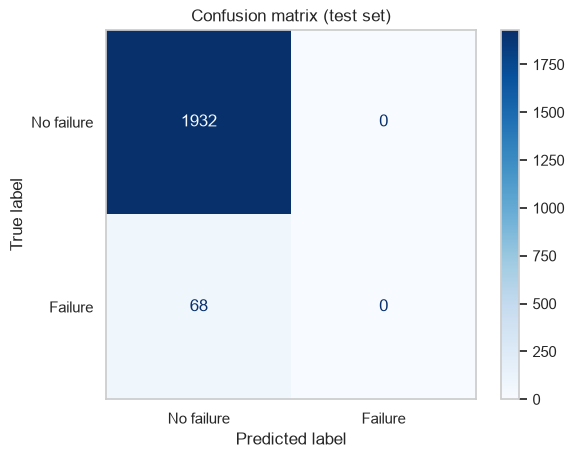

Missed failures (FN): 68 | False alarms (FP): 0 | Caught failures (TP): 0


In [158]:
y_predict = anova_svc.predict(x_test)
model_eval(y_predict, y_test)


2. Decision Tree

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.990     0.987     0.988      1932
     Failure      0.658     0.706     0.681        68

    accuracy                          0.978      2000
   macro avg      0.824     0.846     0.835      2000
weighted avg      0.978     0.978     0.978      2000



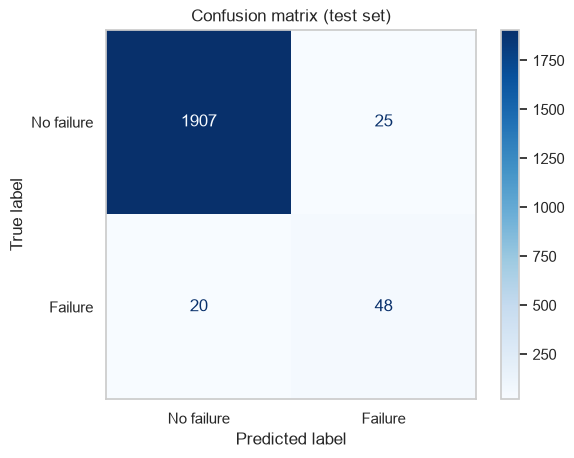

Missed failures (FN): 20 | False alarms (FP): 25 | Caught failures (TP): 48


In [125]:
anova_dtc = make_pipeline(StandardScaler(), anova_filter, DecisionTreeClassifier())
anova_dtc.fit(x_train, y_train)

selector = anova_dtc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_dtc.predict(x_test)
model_eval(y_predict, y_test)


3. Random Forest Classifier

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.989     0.998     0.993      1932
     Failure      0.920     0.676     0.780        68

    accuracy                          0.987      2000
   macro avg      0.954     0.837     0.886      2000
weighted avg      0.986     0.987     0.986      2000



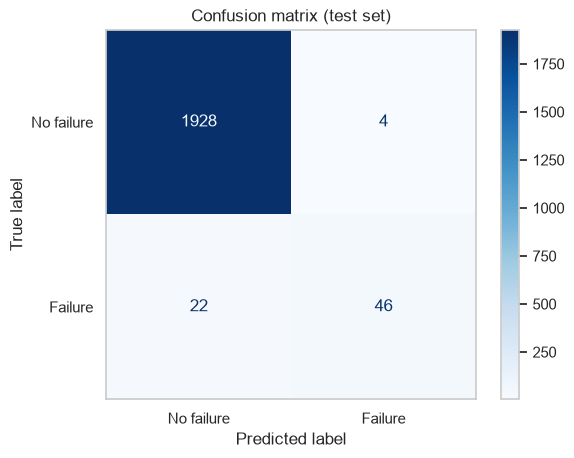

Missed failures (FN): 22 | False alarms (FP): 4 | Caught failures (TP): 46


In [126]:
anova_rfc = make_pipeline(StandardScaler(), anova_filter, RandomForestClassifier())
anova_rfc.fit(x_train, y_train)

selector = anova_rfc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_rfc.predict(x_test)
model_eval(y_predict, y_test)


4. MLP

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.991     0.994     0.992      1932
     Failure      0.806     0.735     0.769        68

    accuracy                          0.985      2000
   macro avg      0.899     0.865     0.881      2000
weighted avg      0.984     0.985     0.985      2000



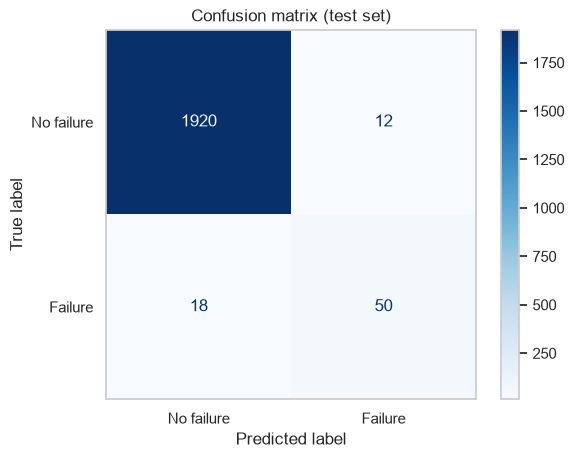

Missed failures (FN): 18 | False alarms (FP): 12 | Caught failures (TP): 50


In [237]:
anova_mlp = make_pipeline(StandardScaler(), anova_filter, MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000, random_state = 55)) # try: 8, 8 - 16, 8 - 16, 16
anova_mlp.fit(x_train, y_train)

selector = anova_mlp.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_mlp.predict(x_test)
model_eval(y_predict, y_test)


5. Logistic Regression

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.974     0.997     0.985      1932
     Failure      0.762     0.235     0.360        68

    accuracy                          0.972      2000
   macro avg      0.868     0.616     0.672      2000
weighted avg      0.967     0.972     0.964      2000



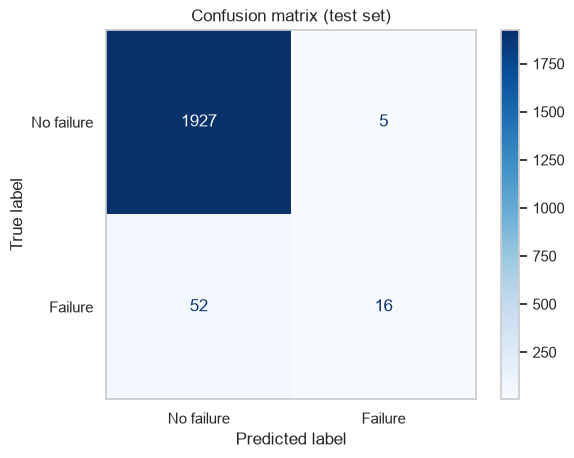

Missed failures (FN): 52 | False alarms (FP): 5 | Caught failures (TP): 16


In [174]:
anova_lr = make_pipeline(StandardScaler(), anova_filter, LogisticRegression())
anova_lr.fit(x_train, y_train)

selector = anova_lr.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_lr.predict(x_test)
model_eval(y_predict, y_test)


# 2. Recursive Feature Selection - RFE

1. SVC

Selected: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']
              precision    recall  f1-score   support

  No failure      0.973     0.999     0.986      1932
     Failure      0.938     0.221     0.357        68

    accuracy                          0.973      2000
   macro avg      0.955     0.610     0.672      2000
weighted avg      0.972     0.973     0.965      2000



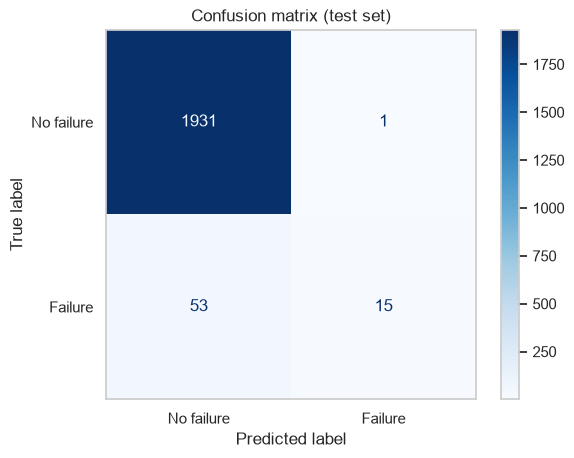

Missed failures (FN): 53 | False alarms (FP): 1 | Caught failures (TP): 15


In [176]:
base_svc = SVC(kernel='linear')
rfe_svc = RFE(base_svc, n_features_to_select = 5)
rfe_svc.fit(x_train, y_train)

mask = rfe_svc.get_support()
print("Selected:", x_train.columns[mask].tolist())
y_predict = rfe_svc.predict(x_test)
model_eval(y_predict, y_test)

2. Decision Tree

Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.989     0.986     0.987      1932
     Failure      0.630     0.676     0.652        68

    accuracy                          0.976      2000
   macro avg      0.809     0.831     0.820      2000
weighted avg      0.976     0.976     0.976      2000



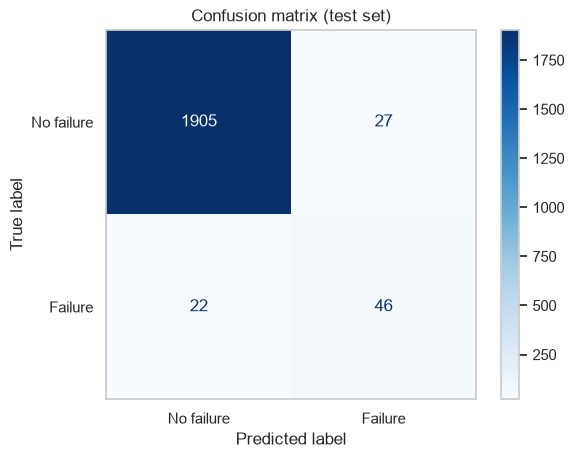

Missed failures (FN): 22 | False alarms (FP): 27 | Caught failures (TP): 46


In [160]:
base_dtc = DecisionTreeClassifier()
rfe_dtc = RFE(base_dtc, n_features_to_select = 5)
rfe_dtc.fit(x_train, y_train)

mask = rfe_dtc.get_support()
print("Selected:", x_train.columns[mask].tolist())
y_predict = rfe_dtc.predict(x_test)
model_eval(y_predict, y_test)

3. Random Forest

Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.990     0.997     0.994      1932
     Failure      0.906     0.706     0.793        68

    accuracy                          0.988      2000
   macro avg      0.948     0.852     0.893      2000
weighted avg      0.987     0.988     0.987      2000



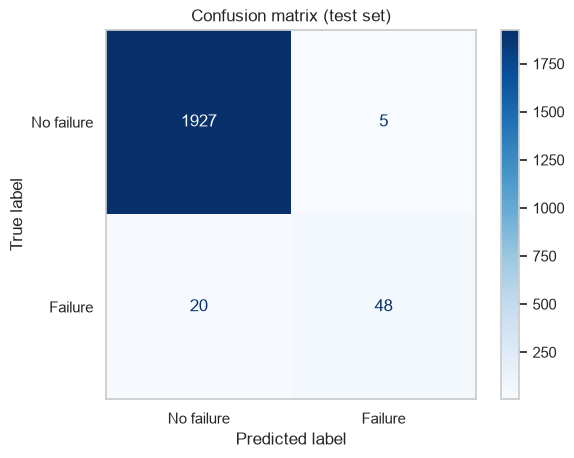

Missed failures (FN): 20 | False alarms (FP): 5 | Caught failures (TP): 48


In [161]:
base_rfc = RandomForestClassifier()
rfe_rfc = RFE(base_rfc, n_features_to_select = 5)
rfe_rfc.fit(x_train, y_train)

mask = rfe_rfc.get_support()
print("Selected:", x_train.columns[mask].tolist())
y_predict = rfe_rfc.predict(x_test)
model_eval(y_predict, y_test)

4. MLP

Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.975     0.999     0.987      1932
     Failure      0.947     0.265     0.414        68

    accuracy                          0.975      2000
   macro avg      0.961     0.632     0.700      2000
weighted avg      0.974     0.975     0.967      2000



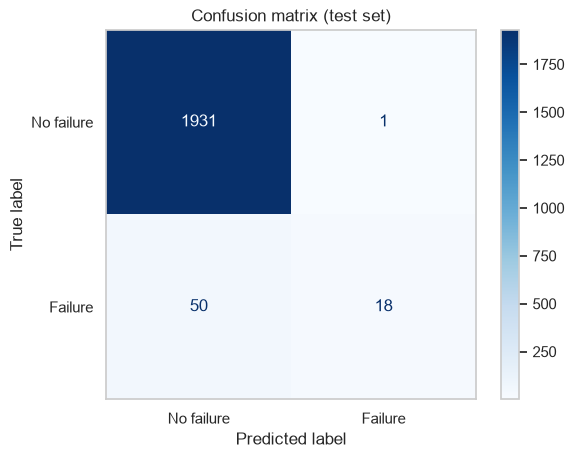

Missed failures (FN): 50 | False alarms (FP): 1 | Caught failures (TP): 18


In [238]:
base_svc = SVC(kernel = "linear")

rfe = RFE(base_rfc, n_features_to_select = 5)

x_train_rfe = rfe.fit_transform(x_train, y_train)
x_test_rfe  = rfe.transform(x_test)

mask = rfe.get_support()
print("Selected:", x_train.columns[mask].tolist())
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train_rfe, y_train)
y_predict = mlp.predict(x_test_rfe)
model_eval(y_predict, y_test)

Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.971     0.998     0.984      1932
     Failure      0.769     0.147     0.247        68

    accuracy                          0.970      2000
   macro avg      0.870     0.573     0.616      2000
weighted avg      0.964     0.970     0.959      2000



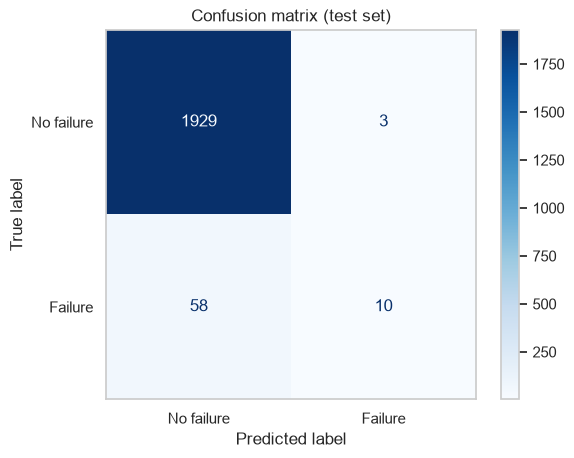

Missed failures (FN): 58 | False alarms (FP): 3 | Caught failures (TP): 10


In [239]:
base_rfc = RandomForestClassifier()

rfe = RFE(base_rfc, n_features_to_select = 5)

x_train_rfe = rfe.fit_transform(x_train, y_train)
x_test_rfe  = rfe.transform(x_test)

mask = rfe.get_support()
print("Selected:", x_train.columns[mask].tolist())
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train_rfe, y_train)
y_predict = mlp.predict(x_test_rfe)
model_eval(y_predict, y_test)

Selected: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.979     0.998     0.989      1932
     Failure      0.900     0.397     0.551        68

    accuracy                          0.978      2000
   macro avg      0.940     0.698     0.770      2000
weighted avg      0.976     0.978     0.974      2000



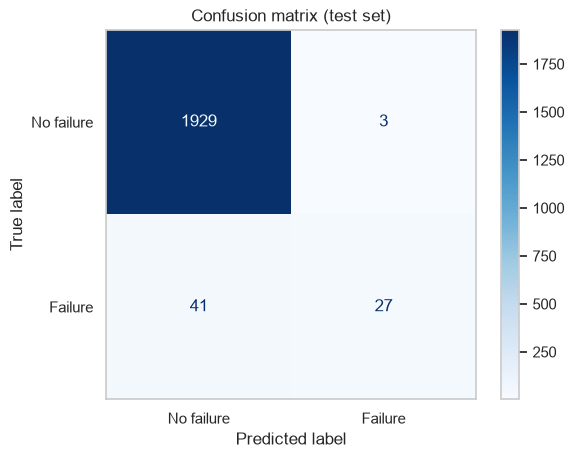

Missed failures (FN): 41 | False alarms (FP): 3 | Caught failures (TP): 27


In [240]:
base_lr = LogisticRegression()

rfe = RFE(base_lr, n_features_to_select = 5)

x_train_rfe = rfe.fit_transform(x_train, y_train)
x_test_rfe  = rfe.transform(x_test)

mask = rfe.get_support()
print("Selected:", x_train.columns[mask].tolist())
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train_rfe, y_train)
y_predict = mlp.predict(x_test_rfe)
model_eval(y_predict, y_test)

5. Logistic Regression

Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.989     0.997     0.993      1932
     Failure      0.902     0.676     0.773        68

    accuracy                          0.987      2000
   macro avg      0.945     0.837     0.883      2000
weighted avg      0.986     0.987     0.986      2000



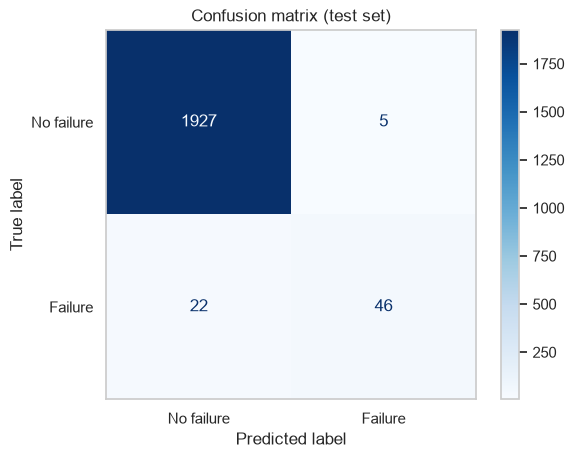

Missed failures (FN): 22 | False alarms (FP): 5 | Caught failures (TP): 46


In [177]:
base_lr = LogisticRegression()
rfe_lr = RFE(base_rfc, n_features_to_select = 5)
rfe_lr.fit(x_train, y_train)

mask = rfe_lr.get_support()
print("Selected:", x_train.columns[mask].tolist())
y_predict = rfe_lr.predict(x_test)
model_eval(y_predict, y_test)

# 3. PCA

In [179]:
from sklearn.decomposition import PCA

[0.319 0.307 0.168 0.165 0.021 0.02 ]
[0.319 0.625 0.794 0.959 0.98  1.   ]


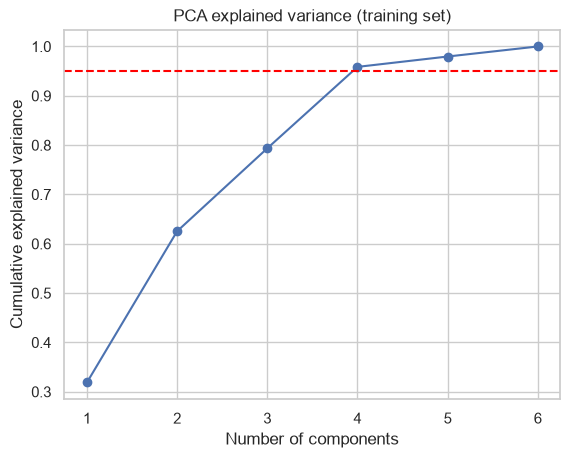

In [180]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

pca_full = PCA(random_state=42).fit(x_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print(np.round(pca_full.explained_variance_ratio_, 3))
print(np.round(cum, 3))

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="red", ls="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.show()

In [183]:
pca = PCA(n_components=0.95, random_state=42)   # keep enough components for 95% variance
x_train_pca = pca.fit_transform(x_train_s)
x_test_pca = pca.transform(x_test_s)
print("Components kept:", pca.n_components_)

Components kept: 4


1. SVC

              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

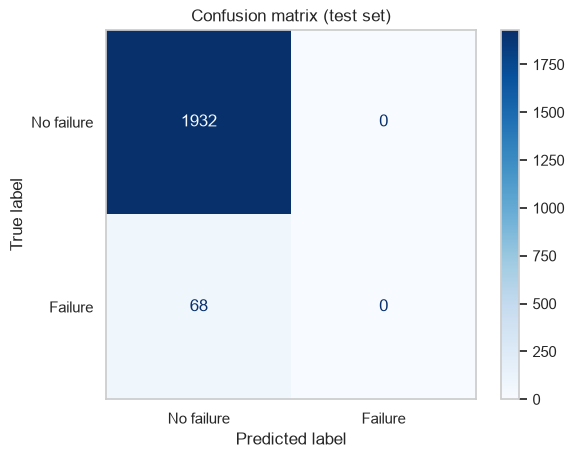

Missed failures (FN): 68 | False alarms (FP): 0 | Caught failures (TP): 0


In [185]:
svc = SVC(kernel = "linear")
svc.fit(x_train_pca, y_train)
y_predict = svc.predict(x_test_pca)
model_eval(y_predict, y_test)

2. Decision Tree

              precision    recall  f1-score   support

  No failure      0.980     0.976     0.978      1932
     Failure      0.382     0.426     0.403        68

    accuracy                          0.957      2000
   macro avg      0.681     0.701     0.690      2000
weighted avg      0.959     0.957     0.958      2000



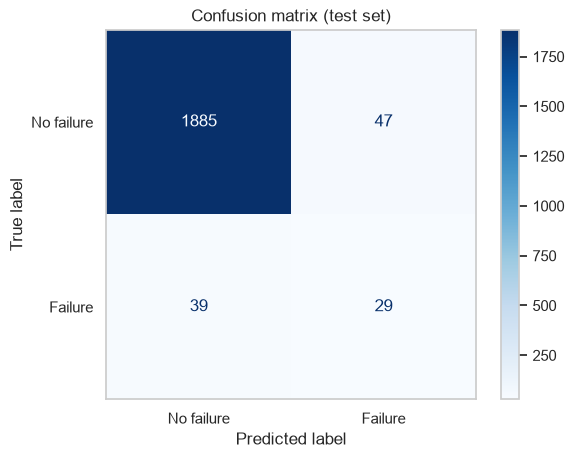

Missed failures (FN): 39 | False alarms (FP): 47 | Caught failures (TP): 29


In [186]:
dtc = DecisionTreeClassifier()
dtc.fit(x_train_pca, y_train)
y_predict = dtc.predict(x_test_pca)
model_eval(y_predict, y_test)

3. Random Forest

              precision    recall  f1-score   support

  No failure      0.975     0.994     0.984      1932
     Failure      0.613     0.279     0.384        68

    accuracy                          0.970      2000
   macro avg      0.794     0.637     0.684      2000
weighted avg      0.963     0.970     0.964      2000



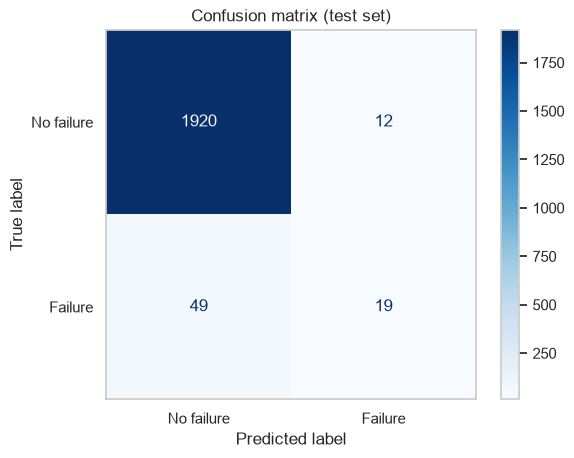

Missed failures (FN): 49 | False alarms (FP): 12 | Caught failures (TP): 19


In [187]:
rfc = RandomForestClassifier()
rfc.fit(x_train_pca, y_train)
y_predict = rfc.predict(x_test_pca)
model_eval(y_predict, y_test)

4. MLP

              precision    recall  f1-score   support

  No failure      0.978     0.996     0.987      1932
     Failure      0.774     0.353     0.485        68

    accuracy                          0.975      2000
   macro avg      0.876     0.675     0.736      2000
weighted avg      0.971     0.975     0.970      2000



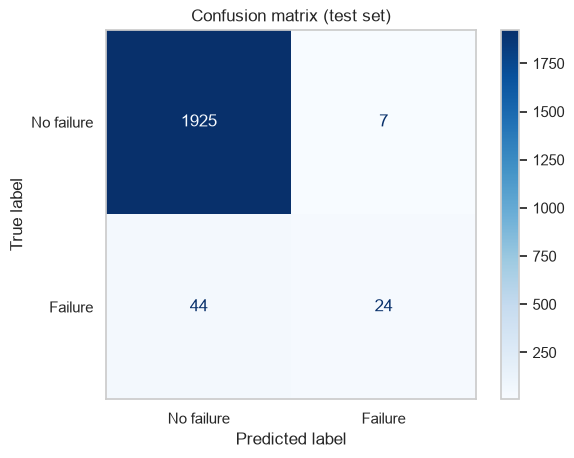

Missed failures (FN): 44 | False alarms (FP): 7 | Caught failures (TP): 24


In [241]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train_pca, y_train)
y_predict = mlp.predict(x_test_pca)
model_eval(y_predict, y_test)

5. Logistic Regression

              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

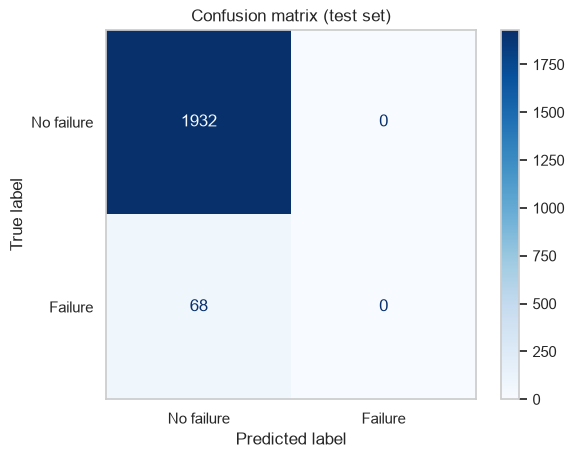

Missed failures (FN): 68 | False alarms (FP): 0 | Caught failures (TP): 0


In [189]:
lr = LogisticRegression()
lr.fit(x_train_pca, y_train)
y_predict = lr.predict(x_test_pca)
model_eval(y_predict, y_test)

# without feature selection

1. SVC

              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      1.000     0.015     0.029        68

    accuracy                          0.967      2000
   macro avg      0.983     0.507     0.506      2000
weighted avg      0.968     0.967     0.951      2000



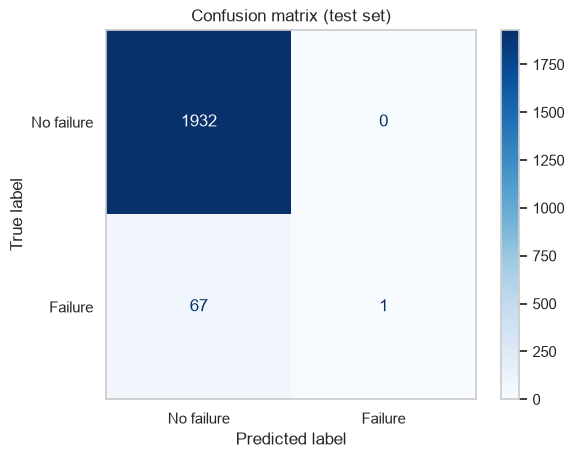

Missed failures (FN): 67 | False alarms (FP): 0 | Caught failures (TP): 1


In [200]:
svc = SVC()
svc.fit(x_train, y_train)
y_predict = svc.predict(x_test)
model_eval(y_predict, y_test)

2. Decision tree

              precision    recall  f1-score   support

  No failure      0.989     0.988     0.989      1932
     Failure      0.671     0.691     0.681        68

    accuracy                          0.978      2000
   macro avg      0.830     0.840     0.835      2000
weighted avg      0.978     0.978     0.978      2000



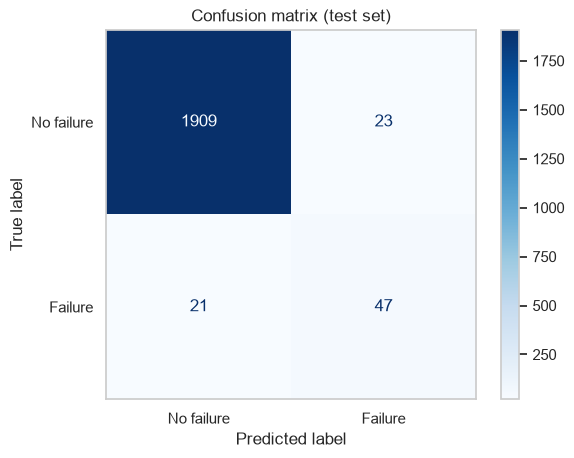

Missed failures (FN): 21 | False alarms (FP): 23 | Caught failures (TP): 47


In [201]:
dtc = DecisionTreeClassifier()
dtc.fit(x_train, y_train)
y_predict = dtc.predict(x_test)
model_eval(y_predict, y_test)

3. Random Forest

              precision    recall  f1-score   support

  No failure      0.989     0.998     0.994      1932
     Failure      0.940     0.691     0.797        68

    accuracy                          0.988      2000
   macro avg      0.965     0.845     0.895      2000
weighted avg      0.988     0.988     0.987      2000



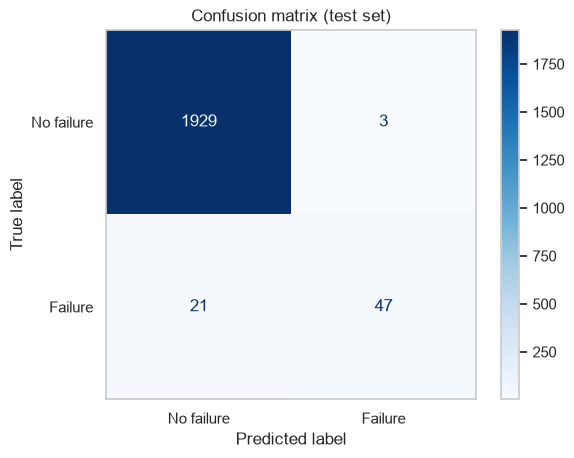

Missed failures (FN): 21 | False alarms (FP): 3 | Caught failures (TP): 47


In [202]:
rfc = RandomForestClassifier()
rfc.fit(x_train, y_train)
y_predict = rfc.predict(x_test)
model_eval(y_predict, y_test)

4. MLP

              precision    recall  f1-score   support

  No failure      0.977     0.993     0.985      1932
     Failure      0.622     0.338     0.438        68

    accuracy                          0.971      2000
   macro avg      0.799     0.665     0.711      2000
weighted avg      0.965     0.971     0.966      2000



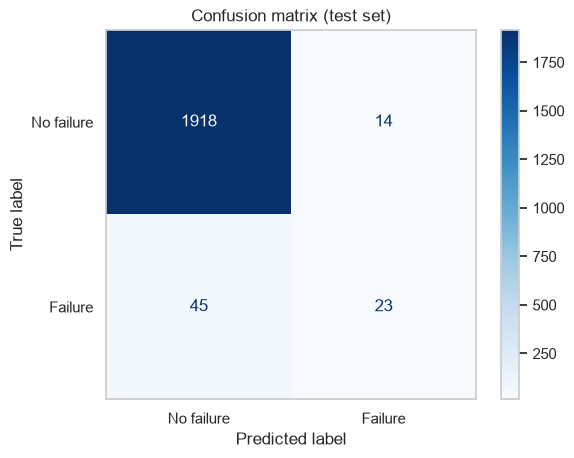

Missed failures (FN): 45 | False alarms (FP): 14 | Caught failures (TP): 23


In [242]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train, y_train)
y_predict = mlp.predict(x_test)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.974     0.996     0.985      1932
     Failure      0.696     0.235     0.352        68

    accuracy                          0.971      2000
   macro avg      0.835     0.616     0.668      2000
weighted avg      0.964     0.971     0.963      2000



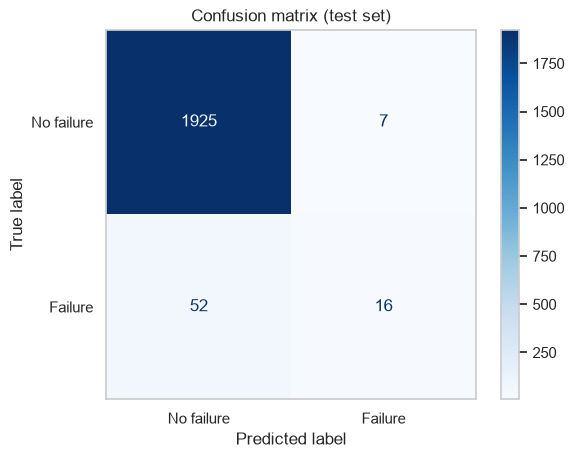

Missed failures (FN): 52 | False alarms (FP): 7 | Caught failures (TP): 16


In [204]:
lr = LogisticRegression()
lr.fit(x_train, y_train)
y_predict = lr.predict(x_test)
model_eval(y_predict, y_test)